# BDB 2027 — Defensive roles from what players *do*, not what the roster calls them

**Goal:** classify every defender in the cohort by the **job he performs**, using game tracking plus results stats (sacks, pressures, run stops, tackles, TFLs, interceptions, pass breakups, coverage assignments). Roster labels are deliberately left out of the inputs. Then:

1. Compare the discovered roles to roster labels, with emphasis on **labeled linebackers and defensive backs**: who is a "safety" doing a linebacker's job, a "linebacker" living in coverage, or a hybrid?
2. Find the **Combine signature of each role**, including *within* a label (e.g. box-role safeties vs. deep-role safeties).
3. Find the **blind spots**: in-game tendencies that define roles but that no current Combine test predicts. Then **propose new drills** to measure them, with a prototype test using drills already in the Combine tracking data.

| § | What |
|---|---|
| 1 | Defensive cohort and the results columns available |
| 2 | Per-rep movement features from game tracking (chunked, cached) |
| 3 | Player-season role profiles: alignment, rush/drop behavior, triggering, range, speed, production |
| 4 | Role discovery: Gaussian mixture with soft membership, so hybrids are visible |
| 5 | Roles vs. roster labels (LB/DB emphasis), mismatches, hybrids, role stability across seasons |
| 6 | Combine trends by role, overall and within label |
| 7 | Can the Combine predict role? (label only vs. Combine vs. both) |
| 8 | Blind-spot analysis: what roles depend on that the Combine can't see |
| 9 | Prototype drill check with existing Combine tracking, and new drill proposals |

**Design choices** (all in the knobs cell):
- **Unit = player-season**, because a player's role can change between years. Player-level summaries are also shown.
- `USE_ALIGNMENT_LABELS = False`: the charted `lined_up_position` is kept out of the clustering by default, so roles come from tracking geometry (depth, width, movement) and results. Set it to `True` to add alignment shares.
- Results stats enter as **rates per 100 snaps**, split by pass and run where it matters.

## 0. Setup

In [1]:
from pathlib import Path
import re as _re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, r2_score, adjusted_rand_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
import warnings
for w in [UserWarning, RuntimeWarning, FutureWarning]: warnings.filterwarnings("ignore", category=w)
warnings.filterwarnings("ignore", message="An input array is constant")

pd.set_option("display.max_columns", 150); pd.set_option("display.width", 230)
sns.set_theme(style="whitegrid", context="notebook")

CANDIDATES = [Path("data"), Path("../data"), Path("data/raw"), Path("/kaggle/input/nfl-big-data-bowl-2027")]
DATA_DIR = next((p for p in CANDIDATES if (p / "games.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("games.csv not found in: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
print("Data dir:", DATA_DIR.resolve())
NULLS = ["NA", "NULL", "null", "None", ""]
def find_csv(stem):
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists(): raise FileNotFoundError(f"{stem}.csv not found under {DATA_DIR.resolve()}")
    return f
def pick(df, candidates, required=False):
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower: return lower[c.lower()]
    if required: raise KeyError(f"None of {candidates} in {list(df.columns)}")
    return None
def zs(s): return (s - s.mean()) / s.std()

# ---- knobs ---------------------------------------------------------------
SEASONS              = [2023, 2024, 2025]
WIN_S                = 6.0     # seconds after snap kept per rep
HS_SPEED             = 7.0     # yd/s high-speed threshold
MIN_SNAPS_SEASON     = 150     # snaps needed for a player-season to be classified
K_RANGE              = range(6, 15)
K_ROLES              = None    # None = choose by BIC; or set an integer (e.g. 10)
USE_ALIGNMENT_LABELS = False   # add charted lined_up_position shares as features
REP_CACHE            = Path("def_rep_features.parquet")
RANDOM               = 27
RNG                  = np.random.default_rng(RANDOM)
SNAP   = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
ARRIVE = {"pass_arrived", "pass_outcome_caught", "pass_outcome_incomplete", "pass_outcome_interception"}
# --------------------------------------------------------------------------

Data dir: C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


## 1. Defensive cohort, labels and results columns

In [2]:
players = pd.read_csv(find_csv("players"), na_values=NULLS)
combine = pd.read_csv(find_csv("combine_results"), na_values=NULLS)
games   = pd.read_csv(find_csv("games"), na_values=NULLS)
pp      = pd.read_csv(find_csv("player_play"), na_values=NULLS, low_memory=False)

prof = players.merge(combine.drop(columns=[c for c in combine if c in players and c != "nfl_id"]), on="nfl_id", how="left")
NAME = pick(prof, ["display_name", "player_name", "full_name", "name"])
NFL_POS, CMB_POS = pick(prof, ["nfl_position", "position"]), pick(prof, ["combine_position"])
DRAFT_YR = pick(prof, ["draft_year"], required=True)
LABEL_MAP = {**{p: "DL" for p in ["DT", "NT", "DE", "DL", "IDL"]}, **{p: "EDGE" for p in ["EDGE", "ED"]},
             **{p: "LB" for p in ["LB", "ILB", "MLB", "OLB", "WLB", "SLB"]},
             **{p: "CB" for p in ["CB", "NB"]}, **{p: "S" for p in ["S", "FS", "SS", "SAF", "DB"]}}
lab = (prof[NFL_POS] if NFL_POS else prof[CMB_POS]).astype(str).str.upper().map(LABEL_MAP)
if CMB_POS: lab = lab.fillna(prof[CMB_POS].astype(str).str.upper().map(LABEL_MAP))
prof["label"] = lab
prof["label_raw"] = (prof[NFL_POS] if NFL_POS else prof[CMB_POS]).astype(str).str.upper()
dfn = prof[prof["label"].notna()].copy()
DEF_IDS = set(dfn["nfl_id"])
print("Defenders by label:", dfn["label"].value_counts().to_dict())
print("Raw position strings:", dfn["label_raw"].value_counts().to_dict())
if (dfn["label"] == "LB").sum() < 10:
    print("⚠ Few labeled linebackers in this cohort. LB emphasis will rely on OLB/hybrid players and DBs playing LB-type roles.")

TEAM = pick(pp, ["team_abbr", "club", "team"], required=True)
LUP = pick(pp, ["lined_up_position", "position_at_snap"])
DIR = pick(pp, ["play_direction"]); POSS = pick(pp, ["possession_team"])
YLS, YLN = pick(pp, ["yardline_side"]), pick(pp, ["yardline_number"])
DROP, PRES = pick(pp, ["is_dropback"]), pick(pp, ["pass_result"])
COV_A = pick(pp, ["coverage_assignment", "pff_defensive_coverage_assignment"])
# results-style columns: every candidate that exists becomes a per-100-snap rate
RESULT_CANDIDATES = {
    "tackle": ["tackle", "solo_tackle", "tackles"], "assist": ["assisted_tackle", "assist", "tackle_assist"],
    "tfl": ["tackle_for_loss", "tfl"], "sack": ["sack", "sacks", "half_sack_yards"],
    "pressure": ["pressure", "caused_pressure", "was_pressure"], "quick_pressure": ["quick_pressure"],
    "blitz": ["blitzing", "was_blitzing", "blitz"], "run_stop": ["run_stop", "stop", "run_stops"],
    "interception": ["interception", "had_interception", "int"], "pbu": ["pass_defensed", "pass_breakup", "pass_deflection"],
    "forced_fumble": ["forced_fumble", "forced_fumbles"], "missed_tackle": ["missed_tackle", "missed_tackles"]}
RES = {k: pick(pp, v) for k, v in RESULT_CANDIDATES.items()}
RES = {k: v for k, v in RES.items() if v}
GETOFF = pick(pp, ["player_get_off", "get_off"])
print("Results columns found:", RES, "| get-off col:", GETOFF, "| coverage col:", COV_A)
missing = sorted(set(RESULT_CANDIDATES) - set(RES))
if missing: print("Not found (add the real column names to RESULT_CANDIDATES if they exist):", missing)

gcols = ["game_id", "season", "week"] + [c for c in ["season_type"] if c in games]
cp = pp[pp["nfl_id"].isin(DEF_IDS)].merge(games[gcols], on="game_id", how="left")
if "season_type" in cp: cp = cp[cp["season_type"].fillna("REG") == "REG"]
cp["is_pass"] = cp[DROP].astype(str).str.lower().isin(["true", "1"]) if DROP else (cp[PRES].notna() if PRES else True)
if all([POSS, YLS, YLN, DIR]):
    own = cp[YLS] == cp[POSS]; right = cp[DIR] == "right"
    cp["los_x"] = np.select([right & own, right & ~own, ~right & own], [10 + cp[YLN], 110 - cp[YLN], 110 - cp[YLN]], 10 + cp[YLN])
else:
    cp["los_x"] = np.nan; print("⚠ LOS columns missing — depth features unavailable")
cp["sgn"] = np.where(cp[DIR] == "left", -1, 1) if DIR else 1
for k, c in RES.items(): cp[f"r_{k}"] = pd.to_numeric(cp[c].replace({True: 1, False: 0, "TRUE": 1, "FALSE": 0, "True": 1, "False": 0}), errors="coerce").fillna(0)
a = cp[COV_A].astype(str).str.upper() if COV_A else pd.Series("", index=cp.index)
DEEP_CODES = {"2L", "2R", "3L", "3M", "3R", "4IL", "4IR", "4OL", "4OR", "DF"}
cp["cov_man"] = a.str.contains("MAN|PRE"); cp["cov_deep"] = a.isin(DEEP_CODES) | a.str.contains("DEEP|HALF|QUARTER|THIRD")
cp["cov_under"] = a.str.contains("HOOK|CURL|FLAT|HOL|CFL|CFR|FL$|FR$|UNDER", regex=True) & ~cp["cov_deep"]
if LUP:
    up = cp[LUP].astype(str).str.upper()
    cp["al"] = np.select([up.str.contains("EDGE|DE"), up.str.contains("INTERIOR|DT|NT|IDL"), up.str.contains("SLOT|NICKEL"),
                          up.str.contains("CB"), up.str.contains("FS|SS|SAF|^S$", regex=True), up.str.contains("LB|MIKE|WILL|SAM")],
                         ["edge", "interior", "slot", "corner", "safety", "box_lb"], "other")
    print("lined_up_position (defense):", up.value_counts().head(15).to_dict())

Defenders by label: {'DL': 88, 'CB': 60, 'S': 59, 'LB': 33}
Raw position strings: {'CB': 60, 'DT': 47, 'DE': 36, 'OLB': 30, 'SS': 28, 'FS': 25, 'NT': 5, 'DB': 5, 'ILB': 2, 'RB': 1, 'MLB': 1}
Results columns found: {'tackle': 'tackle', 'assist': 'assist', 'tfl': 'tackle_for_loss', 'sack': 'sack', 'quick_pressure': 'quick_pressure', 'blitz': 'blitzing'} | get-off col: player_get_off | coverage col: coverage_assignment
Not found (add the real column names to RESULT_CANDIDATES if they exist): ['forced_fumble', 'interception', 'missed_tackle', 'pbu', 'pressure', 'run_stop']
lined_up_position (defense): {'EDGE': 30054, 'CB': 28686, 'INTERIOR_LINE': 23140, 'HIGH_SAFETY': 19337, 'SLOT_CB': 11693, 'OLB': 4968, 'MLB': 1336, 'BOX_SAFETY': 222, 'NAN': 61, 'RB': 19, 'FB': 5, 'TE': 2, 'WR': 1, 'SLOT_WR': 1}


## 2. Per-rep movement features (all defenders, chunked + cached)

Coordinates are standardized so the offense moves toward +x. **Depth** is yards on the defensive side of the LOS (positive = off the ball). **Width** is yards from the nearest sideline.

| feature | meaning |
|---|---|
| `depth_snap`, `width_snap` | alignment at the snap |
| `rushed`, `t_cross` | crossed the LOS within 3 s, and how fast (rush/penetration) |
| `dropped`, `max_drop` | retreated ≥ 3 yd from his snap depth (coverage drop), and how far |
| `bail_1s` | depth change in the first second (+ bail/backpedal, − attack downhill) |
| `trigger_t` | after retreating ≥ 1 yd, time from deepest point until he's driving **forward** at ≥ 3 yd/s. This measures read-and-trigger quickness. |
| `lat_range` | max lateral distance from his snap spot (range) |
| `peak_speed`, `hs_s`, `peak_accel`, `peak_decel` | speed and intensity |
| `close_speed` | mean speed while the ball is in the air |
| `get_off` | time to move 0.5 yd |

In [3]:
ctx = cp[["game_id", "play_id", "nfl_id", "los_x", "sgn"]].drop_duplicates(["game_id", "play_id", "nfl_id"])

def rep_feats(f):
    k = ["game_id", "play_id", "nfl_id"]
    f = f.merge(ctx, on=k, how="inner").sort_values(k + ["time"])
    if f.empty: return pd.DataFrame()
    snap = f.loc[f["event"].isin(SNAP)].groupby(k)["time"].min().rename("snap_time")
    f = f.merge(snap, left_on=k, right_index=True)
    f["t"] = (f["time"] - f["snap_time"]).dt.total_seconds()
    f = f[(f["t"] >= 0) & (f["t"] <= WIN_S)]
    if f.empty: return pd.DataFrame()
    g = f.groupby(k); keys = [f[c] for c in k]
    f["depth"] = f["sgn"] * (f["x"] - f["los_x"])
    d0 = g["depth"].transform("first"); x0, y0 = g["x"].transform("first"), g["y"].transform("first")
    f["disp"] = np.hypot(f["x"] - x0, f["y"] - y0)
    dt = g["t"].diff()
    f["dv"] = (g["s"].diff() / dt).where(dt <= 0.25)
    f["vdepth"] = (g["depth"].diff() / dt).where(dt <= 0.25)           # + = moving away from LOS
    early = f["t"] <= 3.0
    # trigger: deepest point (after ≥1 yd retreat) → first frame moving forward at ≥3 yd/s
    f["dgain"] = f["depth"] - d0
    imax = f[early].groupby(k)["depth"].idxmax()
    tmax = f.loc[imax.values, k + ["t"]].rename(columns={"t": "t_maxd"})
    f = f.merge(tmax, on=k, how="left")
    g = f.groupby(k); keys = [f[c] for c in k]; early = f["t"] <= 3.0; d0 = g["depth"].transform("first")
    x0, y0 = g["x"].transform("first"), g["y"].transform("first")
    maxgain = f["dgain"].where(early).groupby(keys).transform("max")
    trig_cand = (f["t"] > f["t_maxd"]) & (f["vdepth"] <= -3) & (maxgain >= 1)
    f["t_pf"] = f["t"].where(f["event"] == "pass_forward").groupby(keys).transform("min")
    f["t_arr"] = f["t"].where(f["event"].isin(ARRIVE)).groupby(keys).transform("min")
    air = f["t"].between(f["t_pf"], f["t_arr"])
    at1 = f["t"].between(0.95, 1.05)
    out = pd.DataFrame({
        "depth_snap": g["depth"].first(), "width_snap": g["y"].first().pipe(lambda y: np.minimum(y, 53.3 - y)),
        "t_cross": f["t"].where(early & (f["depth"] < -0.5)).groupby(keys).min(),
        "max_drop": f["dgain"].where(early).groupby(keys).max(),
        "bail_1s": f["dgain"].where(at1).groupby(keys).first(),
        "trigger_t": (f["t"].where(trig_cand).groupby(keys).min() - f["t_maxd"].groupby(keys).first()),
        "lat_range": (f["y"] - y0).abs().where(f["t"] <= 4).groupby(keys).max(),
        "get_off": f["t"].where(f["disp"] >= 0.5).groupby(keys).min(),
        "peak_speed": g["s"].max(), "hs_s": (f["s"] >= HS_SPEED).groupby(keys).sum() * 0.1,
        "peak_accel": f["dv"].groupby(keys).max(), "peak_decel": (-f["dv"]).groupby(keys).max(),
        "close_speed": f["s"].where(air).groupby(keys).mean(), "n_frames": g.size()})
    out["rushed"] = out["t_cross"].notna().astype(float)
    out["dropped"] = (out["max_drop"] >= 3).astype(float)
    return out[out["n_frames"] >= 15].reset_index()

if REP_CACHE.exists():
    rep = pd.read_parquet(REP_CACHE); print("loaded", REP_CACHE)
else:
    parts, use = [], ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "event"]
    for season in SEASONS:
        if not (DATA_DIR / f"game_tracking_{season}.csv").exists(): print(f"no game_tracking_{season}.csv — skipped"); continue
        carry = None
        for ch in pd.read_csv(find_csv(f"game_tracking_{season}"), usecols=use, chunksize=2_000_000, na_values=NULLS):
            ch = ch[ch["nfl_id"].isin(DEF_IDS)]
            ch["time"] = pd.to_datetime(ch["time"], errors="coerce")
            if carry is not None: ch = pd.concat([carry, ch], ignore_index=True)
            if ch.empty: continue
            last = ch["game_id"].iloc[-1]; carry = ch[ch["game_id"] == last]; ch = ch[ch["game_id"] != last]
            if len(ch): parts.append(rep_feats(ch))
        if carry is not None and len(carry): parts.append(rep_feats(carry))
        print(season, "processed")
    rep = pd.concat(parts, ignore_index=True)
    rep = rep[~rep.duplicated(["game_id", "play_id", "nfl_id"], keep=False)]
    rep.to_parquet(REP_CACHE, index=False)
keep_ctx = ["game_id", "play_id", "nfl_id", "season", "is_pass", "cov_man", "cov_deep", "cov_under"] + [f"r_{k}" for k in RES] + (["al"] if LUP else []) + ([GETOFF] if GETOFF else [])
rep = rep.merge(cp[keep_ctx], on=["game_id", "play_id", "nfl_id"], how="left")
print(f"defender reps: {len(rep):,} | players: {rep['nfl_id'].nunique()}")
display(rep[["depth_snap", "width_snap", "rushed", "dropped", "max_drop", "bail_1s", "trigger_t", "lat_range", "peak_speed", "close_speed"]].describe().round(2))

2023 processed
2024 processed
2025 processed
defender reps: 119,439 | players: 194


,depth_snap,width_snap,rushed,dropped,max_drop,bail_1s,trigger_t,lat_range,peak_speed,close_speed
count,119439.00,119439.00,119439.00,119439.00,119439.00,119439.00,9994.00,119439.00,119439.00,59017.00
mean,3.98,19.83,0.36,0.30,2.35,-0.37,1.20,5.86,4.95,3.64
std,4.59,4.65,0.48,0.46,3.29,1.24,0.67,4.02,1.70,1.84
min,-12.94,1.07,0.00,0.00,0.00,-5.94,0.20,0.00,0.00,0.00
25%,0.65,17.21,0.00,0.00,0.00,-1.24,0.70,2.80,3.80,2.18
50%,1.38,20.58,0.00,0.00,0.50,-0.26,0.90,4.92,4.92,3.37
75%,6.53,23.67,1.00,1.00,3.91,0.46,1.60,8.06,6.08,4.86
max,93.47,26.65,1.00,1.00,18.82,5.10,4.00,32.63,13.87,10.08


## 3. Player-season role profiles

Pass plays and run plays are summarized separately where the job differs:
- **Pass:** rush rate, drop rate, alignment, bail, drop depth, trigger time, range, closing speed, coverage shares
- **Run:** downhill movement in the first second (fill), penetration rate, range
- **Everyone:** speed profile, plus results per 100 snaps (tackles, TFL, sacks, pressures, blitzes, run stops, INTs, PBUs, forced fumbles), with pass-only stats per 100 pass snaps and run stops per 100 run snaps

In [4]:
def per100(s): return 100 * s.mean()
P, R = rep[rep["is_pass"] == True], rep[rep["is_pass"] == False]
key = ["nfl_id", "season"]
pa = P.groupby(key).agg(pass_snaps=("play_id", "size"), rush_rate=("rushed", "mean"), drop_rate=("dropped", "mean"),
                        depth_pass=("depth_snap", "median"), width_pass=("width_snap", "median"), bail_pass=("bail_1s", "median"),
                        max_drop=("max_drop", "median"), trigger_t=("trigger_t", "median"), trigger_rate=("trigger_t", lambda s: s.notna().mean()),
                        lat_range_pass=("lat_range", "median"), close_speed=("close_speed", "median"),
                        man_share=("cov_man", "mean"), deep_share=("cov_deep", "mean"), under_share=("cov_under", "mean"))
ru = R.groupby(key).agg(run_snaps=("play_id", "size"), depth_run=("depth_snap", "median"), fill_1s=("bail_1s", lambda s: -s.median()),
                        penetrate_run=("rushed", "mean"), lat_range_run=("lat_range", "median"))
al = rep.groupby(key).agg(snaps=("play_id", "size"), speed_p90=("peak_speed", lambda s: s.quantile(.9)), hs_per_snap=("hs_s", "mean"),
                          accel_p90=("peak_accel", lambda s: s.quantile(.9)), decel_p90=("peak_decel", lambda s: s.quantile(.9)),
                          get_off=("get_off", "median"))
res_all = rep.groupby(key)[[f"r_{k}" for k in RES if k not in ("sack", "pressure", "quick_pressure", "interception", "pbu", "run_stop", "blitz")]].agg(per100)
res_pass = P.groupby(key)[[f"r_{k}" for k in RES if k in ("sack", "pressure", "quick_pressure", "interception", "pbu", "blitz")]].agg(per100)
res_run = R.groupby(key)[[f"r_{k}" for k in RES if k == "run_stop"]].agg(per100)
ps = al.join(pa).join(ru).join(res_all).join(res_pass).join(res_run)
if USE_ALIGNMENT_LABELS and LUP:
    ps = ps.join(pd.crosstab([rep["nfl_id"], rep["season"]], rep["al"], normalize="index").add_prefix("al_"))
ps = ps[ps["snaps"] >= MIN_SNAPS_SEASON].reset_index()
ps = ps.merge(dfn[["nfl_id", "label", "label_raw", NAME, DRAFT_YR]], on="nfl_id", how="left")
ps["season_of_career"] = ps["season"] - ps[DRAFT_YR] + 1
print(f"player-seasons with ≥{MIN_SNAPS_SEASON} snaps: {len(ps)} | players: {ps['nfl_id'].nunique()} | by label:", ps["label"].value_counts().to_dict())
display(ps.groupby("label")[[c for c in ps.columns if pd.api.types.is_numeric_dtype(ps[c]) and c not in ("nfl_id", "season", DRAFT_YR)]].median().T.round(2))

player-seasons with ≥150 snaps: 221 | players: 133 | by label: {'DL': 77, 'CB': 64, 'S': 49, 'LB': 31}


label,CB,DL,LB,S
snaps,506.50,416.00,514.00,524.00
speed_p90,7.76,5.71,6.47,7.57
hs_per_snap,0.28,0.01,0.05,0.23
accel_p90,6.37,5.40,6.05,6.60
decel_p90,6.71,4.83,6.07,6.98
get_off,0.90,0.60,0.60,0.70
pass_snaps,320.00,225.00,321.00,355.00
rush_rate,0.01,0.95,0.89,0.05
drop_rate,0.75,0.01,0.06,0.58
depth_pass,4.53,0.62,0.56,10.96


## 4. Role discovery (position-agnostic)

Features are standardized and PCA-reduced (95% of variance), then fit with a **Gaussian mixture**. Two reasons for a GMM:
- it picks k by **BIC** instead of assuming it
- it gives each player-season a **membership probability** for every role, so a true hybrid shows up as split membership instead of being forced into one box

Roster labels are **not** inputs. Roles are auto-named from their centroids (e.g. *edge rusher*, *interior DL*, *rush/drop hybrid*, *deep safety*, *outside corner*, *slot/nickel*, *box run defender*, *coverage linebacker*, *blitzing box defender*). Rename them in `ROLE_RENAME` once you've looked at them.

role features: ['speed_p90', 'hs_per_snap', 'accel_p90', 'decel_p90', 'get_off', 'rush_rate', 'drop_rate', 'depth_pass', 'width_pass', 'bail_pass', 'max_drop', 'trigger_t', 'trigger_rate', 'lat_range_pass', 'close_speed', 'man_share', 'deep_share', 'under_share', 'depth_run', 'fill_1s', 'penetrate_run', 'lat_range_run', 'r_tackle', 'r_assist', 'r_tfl', 'r_sack', 'r_quick_pressure', 'r_blitz']
PCA: 10 components for 95% variance


  File "c:\Users\bchm5\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\bchm5\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


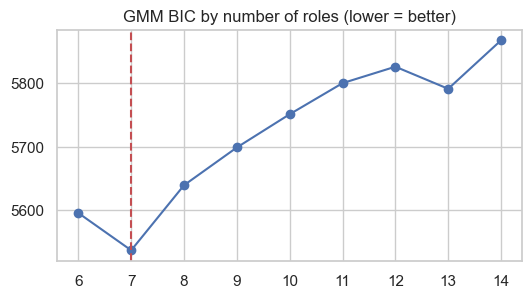

,speed_p90,hs_per_snap,accel_p90,decel_p90,get_off,rush_rate,drop_rate,depth_pass,width_pass,bail_pass,max_drop,trigger_t,trigger_rate,lat_range_pass,close_speed,man_share,deep_share,under_share,depth_run,fill_1s,penetrate_run,lat_range_run,r_tackle,r_assist,r_tfl,r_sack,r_quick_pressure,r_blitz,n
role_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
interior DL · high penetrate_run,6.29,0.05,6.05,5.63,0.56,0.91,0.05,0.60,21.44,-1.80,0.00,1.39,0.01,4.22,2.62,0.01,0.00,0.09,0.68,0.88,0.62,4.82,3.48,3.04,0.93,0.94,2.37,86.58,50
slot/nickel,7.77,0.29,6.31,6.62,0.89,0.01,0.78,4.73,13.49,0.54,6.27,1.23,0.12,5.28,4.56,0.34,0.43,0.16,4.54,-0.27,0.03,5.77,5.34,2.01,0.24,0.03,0.05,0.44,48
deep safety,7.58,0.24,6.55,6.80,0.65,0.04,0.61,11.21,20.89,0.56,4.47,1.21,0.23,5.72,4.08,0.12,0.59,0.20,9.79,-0.11,0.06,5.95,5.90,3.74,0.28,0.07,0.43,3.09,40
coverage linebacker / big nickel · high under_share,6.76,0.09,5.90,6.60,0.70,0.12,0.21,3.99,20.79,-0.39,0.58,1.00,0.03,5.71,3.24,0.07,0.00,0.78,3.62,0.79,0.26,4.78,9.92,4.96,0.83,1.04,0.00,10.42,26
interior DL · low accel_p90,5.45,0.01,5.14,4.64,0.57,0.94,0.01,0.64,23.94,-1.47,0.00,1.19,0.00,3.00,2.08,0.00,0.00,0.01,0.66,0.56,0.37,4.09,2.82,3.91,0.59,0.63,1.31,92.98,41
interior DL · high r_sack,6.15,0.04,5.99,5.57,0.52,0.95,0.02,0.54,22.11,-1.92,0.00,1.28,0.00,4.19,2.55,0.00,0.00,0.04,0.62,0.90,0.63,4.66,4.30,2.30,2.21,2.43,3.92,90.43,16
coverage linebacker / big nickel · high under_share,7.67,0.26,6.71,7.08,0.79,0.07,0.58,4.38,19.29,0.29,3.74,1.20,0.11,6.52,4.16,0.27,0.12,0.50,3.83,0.07,0.12,6.07,6.60,3.05,0.52,0.20,0.94,5.24,26


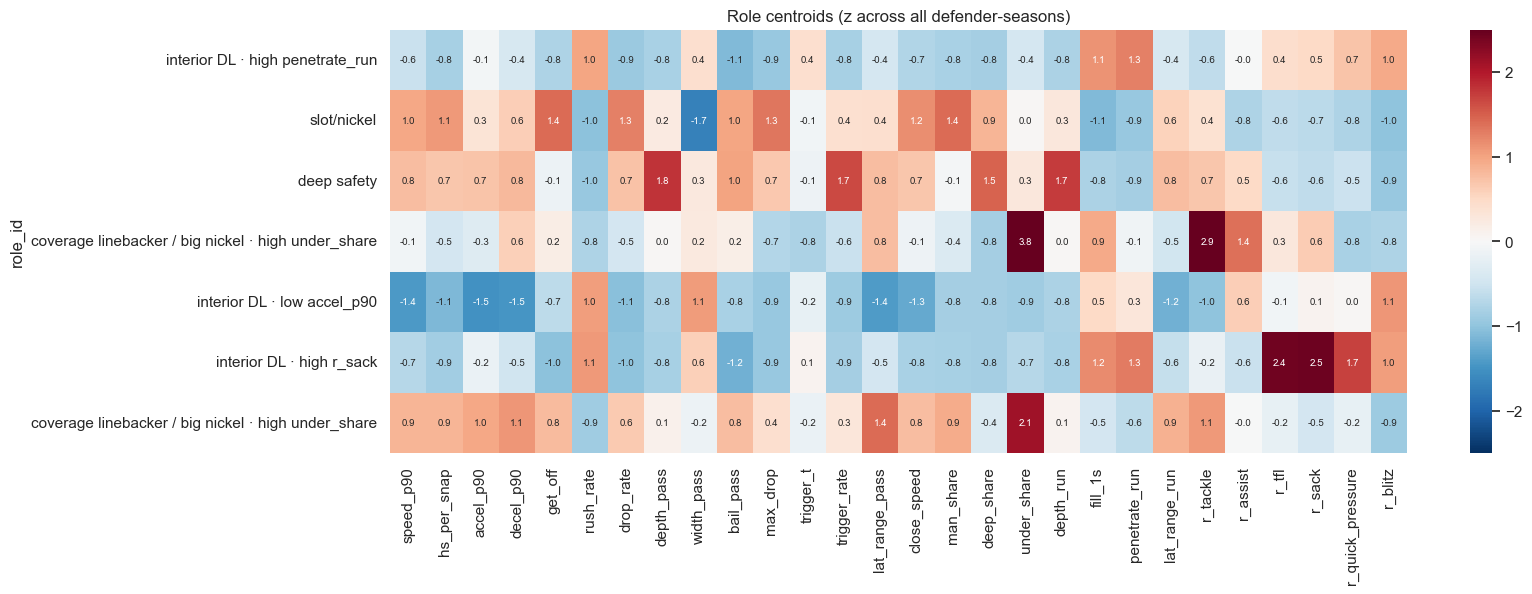

In [5]:
FEAT = [c for c in ps.columns if c not in ("nfl_id", "season", "label", "label_raw", NAME, DRAFT_YR, "season_of_career", "snaps", "pass_snaps", "run_snaps")
        and pd.api.types.is_numeric_dtype(ps[c]) and ps[c].notna().mean() > .6 and ps[c].std() > 0]
print("role features:", FEAT)
imp = SimpleImputer(strategy="median").fit(ps[FEAT])
Xs = StandardScaler().fit_transform(imp.transform(ps[FEAT]))
pca = PCA(n_components=.95, random_state=RANDOM).fit(Xs); Z = pca.transform(Xs)
print(f"PCA: {Z.shape[1]} components for 95% variance")
bic = {k: GaussianMixture(k, covariance_type="diag", n_init=5, random_state=RANDOM).fit(Z).bic(Z) for k in K_RANGE if k < len(Z) // 5}
K = K_ROLES or min(bic, key=bic.get)
plt.figure(figsize=(6, 3)); plt.plot(list(bic), list(bic.values()), "o-"); plt.axvline(K, color="r", ls="--"); plt.title("GMM BIC by number of roles (lower = better)"); plt.show()
gmm = GaussianMixture(K, covariance_type="diag", n_init=10, random_state=RANDOM).fit(Z)
prob = gmm.predict_proba(Z)
ps["role_id"] = prob.argmax(1); ps["role_prob"] = prob.max(1)
ps["hybrid_entropy"] = -(prob * np.log(prob + 1e-12)).sum(1) / np.log(K)       # 0 = pure, 1 = evenly split
raw = pd.DataFrame(imp.transform(ps[FEAT]), columns=FEAT)
cent = raw.groupby(ps["role_id"]).mean()
cz = (cent - raw.mean()) / raw.std()

def g(r, c, d=np.nan): return r[c] if c in r else d
def name_role(r):
    rush, drop, dep, wid = g(r, "rush_rate", 0), g(r, "drop_rate", 0), g(r, "depth_pass", 5), g(r, "width_pass", 20)
    if rush >= .6: return "edge rusher" if g(r, "speed_p90", 0) >= raw["speed_p90"].median() else "interior DL"
    if .2 <= rush < .6: return "rush/drop hybrid"
    if dep >= 10: return "deep safety"
    if wid <= 11: return "outside corner (press)" if dep <= 4 else "outside corner (off)"
    if wid <= 17 and dep <= 7: return "slot/nickel"
    if g(r, "r_blitz", 0) >= raw.get("r_blitz", pd.Series([0])).quantile(.75) and "r_blitz" in raw: return "blitzing box defender"
    if drop >= .5 or g(r, "under_share", 0) + g(r, "man_share", 0) > .5: return "coverage linebacker / big nickel"
    return "box run defender"
names = {i: name_role(cent.loc[i]) for i in cent.index}
s_ = pd.Series(names)
for i in cent.index:
    if (s_ == names[i]).sum() > 1:
        z = cz.loc[i]; top = z.abs().idxmax(); names[i] = f"{names[i]} · {'high' if z[top] > 0 else 'low'} {top}"
ROLE_RENAME = {}                       # e.g. {"box run defender": "Mike/thumper"}
ps["role"] = ps["role_id"].map(names).replace(ROLE_RENAME)
display(cent.rename(index=names).round(2).assign(n=ps.groupby("role").size()))
plt.figure(figsize=(min(1 + .55 * len(FEAT), 26), .5 * K + 2))
sns.heatmap(cz.rename(index=names), annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, annot_kws={"size": 7})
plt.title("Role centroids (z across all defender-seasons)"); plt.show()

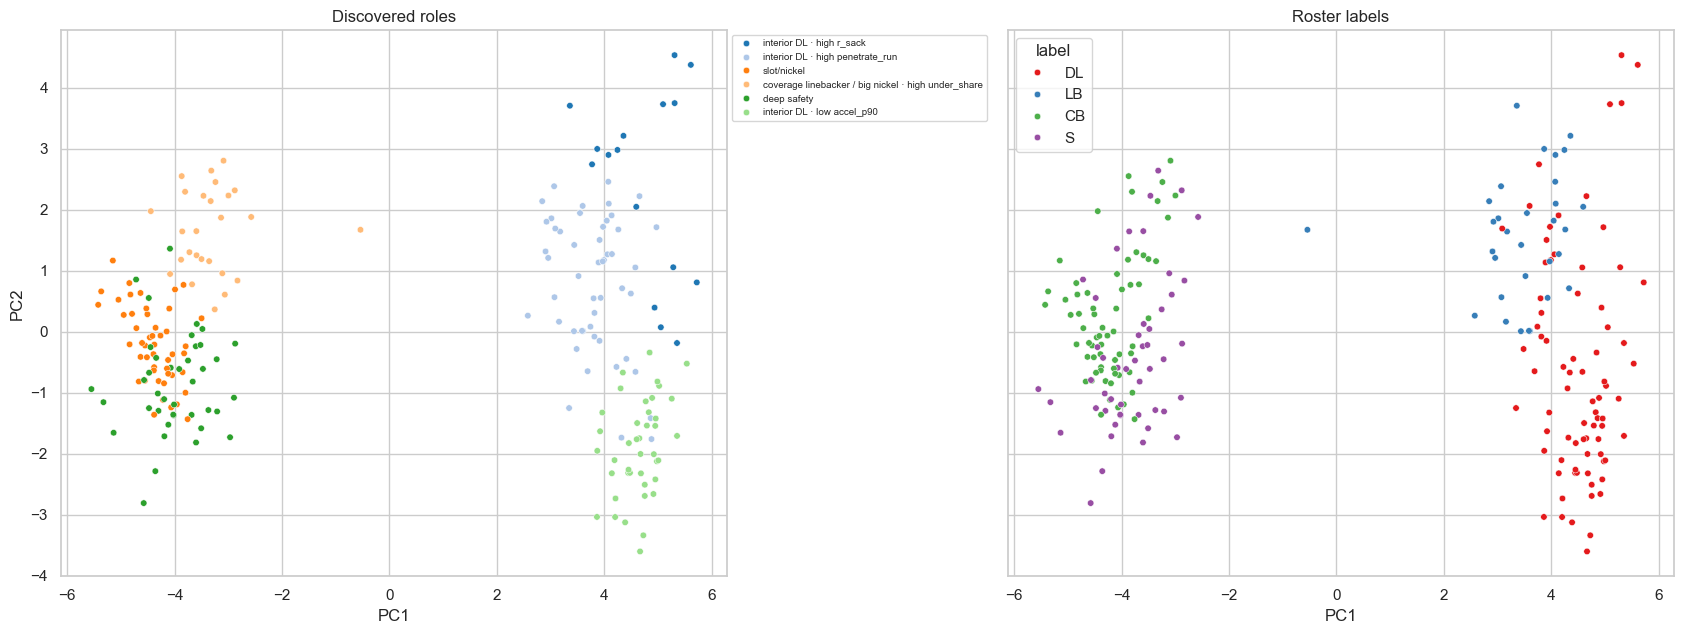

Top loadings:


,PC1,PC2
rush_rate,0.24,NaN
r_blitz,0.24,NaN
drop_rate,0.23,NaN
bail_pass,0.23,NaN
close_speed,0.23,NaN
hs_per_snap,0.22,NaN
r_tfl,NaN,0.37
r_quick_pressure,NaN,0.35
accel_p90,NaN,0.33
r_sack,NaN,0.29


In [6]:
# Map of roles: first two PCA components, colored by discovered role vs by roster label
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), sharex=True, sharey=True)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=ps["role"], ax=axes[0], s=22, palette="tab20"); axes[0].set_title("Discovered roles")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=ps["label"], ax=axes[1], s=22, palette="Set1"); axes[1].set_title("Roster labels")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
axes[0].legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
load = pd.DataFrame(pca.components_[:2].T, index=FEAT, columns=["PC1", "PC2"])
print("Top loadings:"); display(pd.concat([load["PC1"].abs().nlargest(6), load["PC2"].abs().nlargest(6)], axis=1).round(2))

## 5. Roles vs. roster labels (LB and DB emphasis)

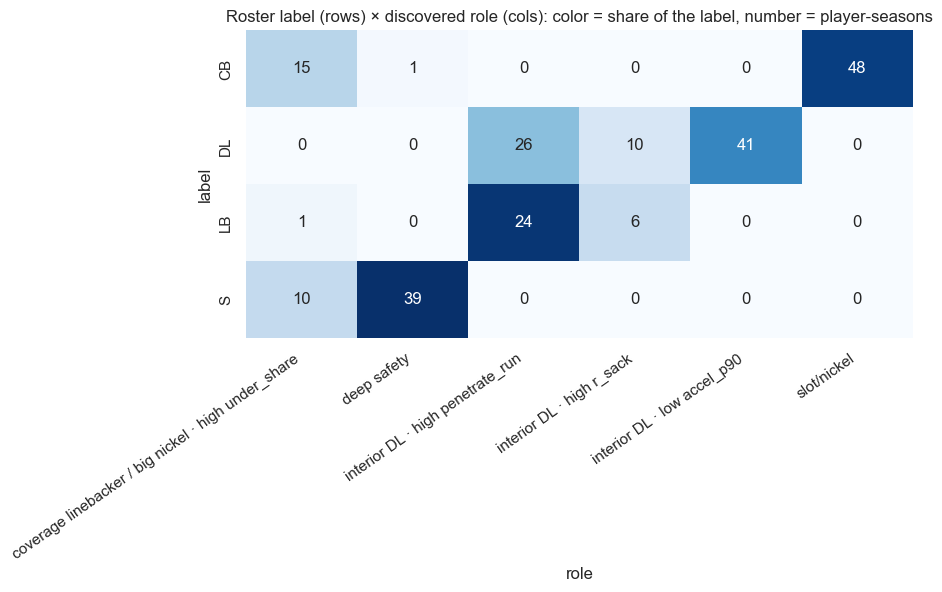

Agreement between roles and roster labels (ARI): 0.537

LB (31 player-seasons): {'interior DL · high penetrate_run': 0.77, 'interior DL · high r_sack': 0.19, 'coverage linebacker / big nickel · high under_share': 0.03}

S (49 player-seasons): {'deep safety': 0.8, 'coverage linebacker / big nickel · high under_share': 0.2}

CB (64 player-seasons): {'slot/nickel': 0.75, 'coverage linebacker / big nickel · high under_share': 0.23, 'deep safety': 0.02}

LB/S/CB player-seasons playing a role that's typical of another label: 42 of 144


,display_name,label_raw,season,role,role_typical_label,role_prob,snaps
166,Jaylon Carlies,MLB,2024,coverage linebacker / big nickel · high under_...,CB,1.000000,242
74,Antonio Johnson,SS,2023,coverage linebacker / big nickel · high under_...,CB,1.000000,171
174,Jaylen Harrell,OLB,2024,interior DL · high penetrate_run,DL,1.000000,286
138,Tykee Smith,SS,2024,coverage linebacker / big nickel · high under_...,CB,1.000000,612
13,Brian Branch,SS,2023,coverage linebacker / big nickel · high under_...,CB,1.000000,735
189,Oluwafemi Oladejo,OLB,2025,interior DL · high penetrate_run,DL,0.999997,241
61,Tavius Robinson,OLB,2023,interior DL · high penetrate_run,DL,0.999997,335
179,Christian Roland-Wallace,CB,2025,deep safety,S,0.999995,190
69,Yasir Abdullah,OLB,2024,interior DL · high penetrate_run,DL,0.999982,169
58,Chamarri Conner,SS,2024,coverage linebacker / big nickel · high under_...,CB,0.999978,573


In [7]:
ct = pd.crosstab(ps["label"], ps["role"])
plt.figure(figsize=(min(2 + 1.1 * ct.shape[1], 24), 4))
sns.heatmap(pd.crosstab(ps["label"], ps["role"], normalize="index"), annot=ct, fmt="d", cmap="Blues", cbar=False)
plt.title("Roster label (rows) × discovered role (cols): color = share of the label, number = player-seasons"); plt.xticks(rotation=35, ha="right"); plt.show()
print(f"Agreement between roles and roster labels (ARI): {adjusted_rand_score(ps['label'], ps['role']):.3f}")

# Where do LBs and DBs actually play?
for L in ["LB", "S", "CB"]:
    d = ps[ps["label"] == L]
    if len(d): print(f"\n{L} ({len(d)} player-seasons):", (d["role"].value_counts(normalize=True).round(2)).to_dict())

# Each label's "home" role = its most common role; mismatches = player-seasons whose role is a different label's home
home = ps.groupby("label")["role"].agg(lambda s: s.value_counts().index[0])
role_home_label = ps.groupby("role")["label"].agg(lambda s: s.value_counts().index[0])
ps["role_typical_label"] = ps["role"].map(role_home_label)
mm = ps[(ps["label"].isin(["LB", "S", "CB"])) & (ps["role_typical_label"] != ps["label"])]
print(f"\nLB/S/CB player-seasons playing a role that's typical of another label: {len(mm)} of {ps['label'].isin(['LB','S','CB']).sum()}")
display(mm.sort_values("role_prob", ascending=False)[[NAME, "label_raw", "season", "role", "role_typical_label", "role_prob", "snaps"]].head(30))

C:\Users\bchm5\AppData\Local\Temp\ipykernel_13120\4050226380.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pairs = multi.groupby("nfl_id").apply(lambda d: pd.Series({"same_role": d["role"].iloc[0] == d["role"].iloc[-1], "label": d["label"].iloc[0]}))


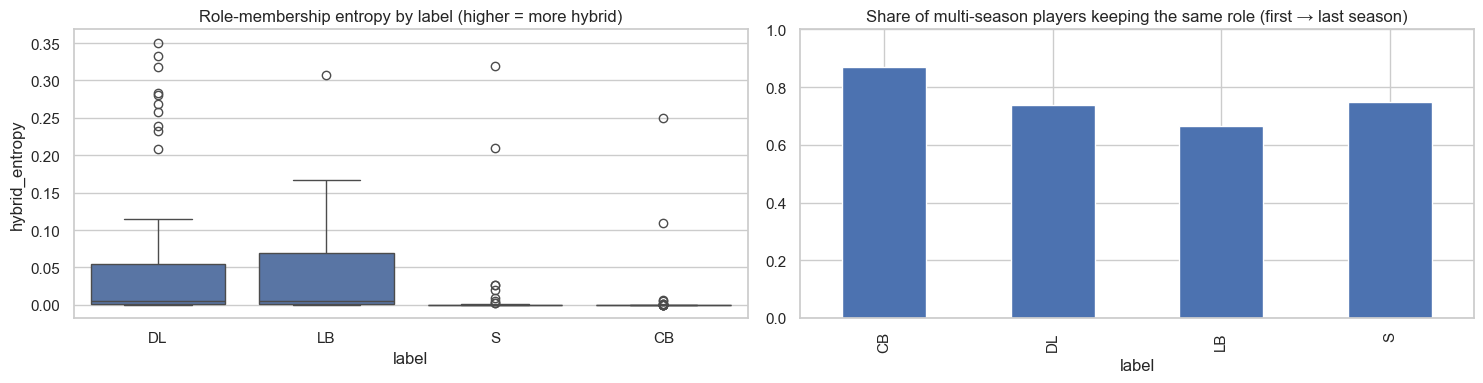

Most hybrid LB/DB player-seasons (top-2 role probabilities):


,display_name,label_raw,season,top2,hybrid_entropy
128,Javon Bullard,SS,2024,coverage linebacker / big nickel · high under_...,0.318800
43,YaYa Diaby,OLB,2025,interior DL · high penetrate_run 72% / interio...,0.307061
71,Cameron Mitchell,CB,2024,coverage linebacker / big nickel · high under_...,0.249562
15,Brian Branch,SS,2025,coverage linebacker / big nickel · high under_...,0.209317
29,Tuli Tuipulotu,OLB,2024,interior DL · high penetrate_run 90% / interio...,0.166997
102,Jared Verse,OLB,2025,interior DL · high penetrate_run 91% / interio...,0.159930
41,YaYa Diaby,OLB,2023,interior DL · high r_sack 91% / interior DL · ...,0.157501
125,Mike Sainristil,CB,2025,slot/nickel 94% / coverage linebacker / big ni...,0.109704
103,Chop Robinson,OLB,2024,interior DL · high r_sack 95% / interior DL · ...,0.097248
8,Will McDonald,OLB,2025,interior DL · high r_sack 96% / interior DL · ...,0.081903


,tackle/100,assist/100,tfl/100,sack/100,quick_pressure/100,blitz/100
role,,,,,,
coverage linebacker / big nickel · high under_share,6.69,3.28,0.39,0.08,0.72,5.20
deep safety,5.71,3.59,0.21,0.00,0.36,2.70
interior DL · high penetrate_run,3.58,2.96,0.90,0.99,2.35,88.98
interior DL · high r_sack,4.73,2.51,2.26,2.44,3.82,91.83
interior DL · low accel_p90,2.81,4.00,0.55,0.60,1.23,93.22
slot/nickel,5.15,1.99,0.18,0.00,0.00,0.22


In [8]:
# Hybrids: how split is each label's membership?  And are roles stable across seasons?
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=ps, x="label", y="hybrid_entropy", order=[l for l in ["DL", "EDGE", "LB", "S", "CB"] if l in set(ps["label"])], ax=axes[0])
axes[0].set_title("Role-membership entropy by label (higher = more hybrid)")
multi = ps.sort_values("season").groupby("nfl_id").filter(lambda d: len(d) >= 2)
if len(multi):
    pairs = multi.groupby("nfl_id").apply(lambda d: pd.Series({"same_role": d["role"].iloc[0] == d["role"].iloc[-1], "label": d["label"].iloc[0]}))
    pairs.groupby("label")["same_role"].mean().plot.bar(ax=axes[1], color="#4C72B0")
    axes[1].set_title("Share of multi-season players keeping the same role (first → last season)"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()
print("Most hybrid LB/DB player-seasons (top-2 role probabilities):")
top2 = pd.DataFrame(prob, columns=[names[i] for i in range(K)]).apply(lambda r: " / ".join(f"{k} {v:.0%}" for k, v in r.nlargest(2).items()), axis=1)
display(ps.assign(top2=top2)[ps["label"].isin(["LB", "S", "CB"])].sort_values("hybrid_entropy", ascending=False)[[NAME, "label_raw", "season", "top2", "hybrid_entropy"]].head(15))

# Production profile by role (results stats only)
RCOLS = [c for c in ps.columns if c.startswith("r_")]
if RCOLS: display(ps.groupby("role")[RCOLS].median().round(2).rename(columns=lambda c: c[2:] + "/100"))

## 6. Combine trends by role

Each player gets his **primary role** (the role of his highest-snap season) and is joined to Combine results and Combine-tracking features:
- top speed and 20-yd time from the sensor 40
- shuttle turn metrics
- **break-forward time** from any drill that includes a backward-to-forward reversal (the closest existing analog to an in-game trigger)

Two views:
- **All defenders:** mean z of each Combine measure by role
- **Within label:** for LBs, safeties and corners separately, how players in each role differ from others *with the same label* (Cohen's d with bootstrap CI). This is the "same label, different job, different athlete?" question.

Combine-tracking features for 240 defenders
players with a primary role and Combine data: 133


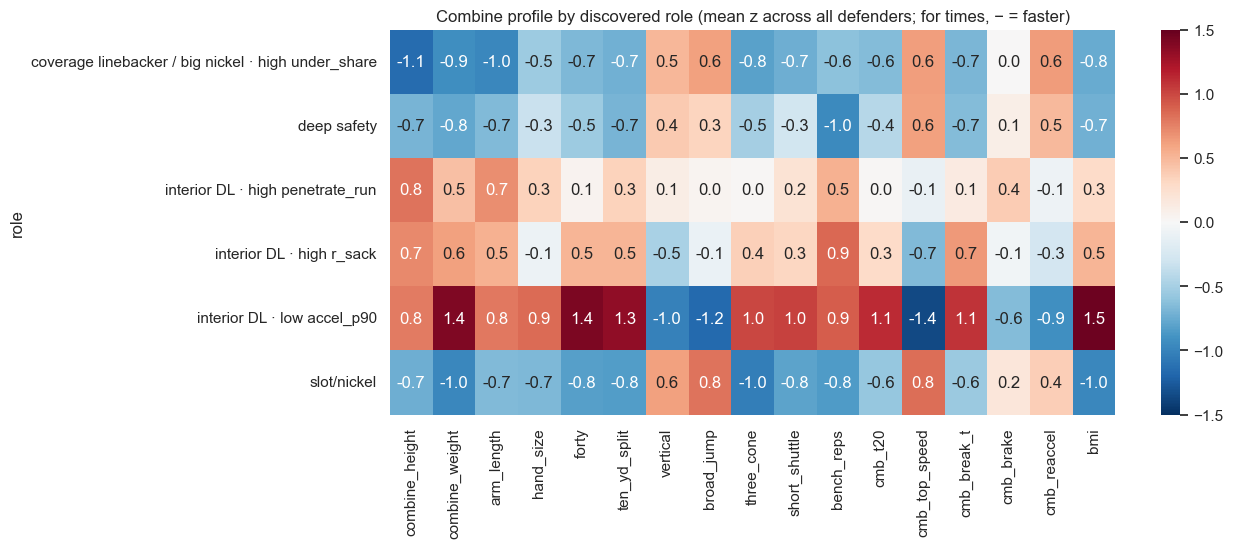

In [9]:
ct_ = pd.read_csv(find_csv("combine_tracking"), na_values=NULLS)
if "entity_type" in ct_: ct_ = ct_[ct_["entity_type"] == "PLAYER"]
ct_ = ct_[ct_["nfl_id"].isin(DEF_IDS)].copy()
ct_["time"] = pd.to_datetime(ct_["time"], errors="coerce"); ct_ = ct_.sort_values(["event_id", "nfl_id", "time"])
DT = pick(ct_, ["drill_type"]); dtype = ct_[DT].astype(str).str.upper() if DT else pd.Series("", index=ct_.index)

def axis_motion(r):
    t = (r["time"] - r["time"].iloc[0]).dt.total_seconds().to_numpy()
    if len(t) < 10 or np.any(np.diff(t) <= 0): return None
    xy = np.c_[r["x"].to_numpy(float), r["y"].to_numpy(float)]
    ax_ = np.linalg.svd(xy - xy.mean(0), full_matrices=False)[2][0]
    pos = (xy - xy[0]) @ ax_
    v = pd.Series(np.gradient(pos, t)).rolling(3, center=True, min_periods=1).mean().to_numpy()
    return t, pos, v

def forty(r):
    o = axis_motion(r)
    if o is None: return None
    t, pos, v = o; mv = np.flatnonzero(np.abs(v) > .5)
    if len(mv) < 5: return None
    d = np.abs(pos[mv[0]:] - pos[mv[0]]); tt = t[mv[0]:] - t[mv[0]]
    return {"cmb_t20": tt[np.argmax(d >= 20)] if (d >= 20).any() else np.nan, "cmb_top_speed": r["s"].max()}

def reversal(r):
    # any drill with a reversal: break time = from the slowest point of the reversal to moving ≥3 yd/s the other way
    o = axis_motion(r)
    if o is None: return None
    t, pos, v = o; sp = np.abs(v)
    sv = np.sign(np.where(sp < .3, 0, v)); nz = np.flatnonzero(sv != 0)
    turns = [nz[j - 1] + int(np.argmin(sp[nz[j - 1]:nz[j] + 1])) for j in range(1, len(nz)) if sv[nz[j]] != sv[nz[j - 1]]]
    if not turns: return None
    bt = []
    for k in turns:
        after = np.flatnonzero((np.arange(len(sp)) > k) & (sp >= 3))
        if len(after): bt.append(t[after[0]] - t[k])
    acc = np.gradient(sp, t)
    return {"cmb_break_t": np.median(bt) if bt else np.nan, "cmb_brake": np.nanmax(-acc), "cmb_reaccel": np.nanmax(acc), "cmb_n_turns": len(turns)}

def per_attempt(mask, fn):
    rows = []
    for (ev, nid), r in ct_[mask].groupby(["event_id", "nfl_id"], sort=False):
        q = fn(r.reset_index(drop=True))
        if q: rows.append({"nfl_id": nid, **q})
    return pd.DataFrame(rows)
f40 = per_attempt(dtype.str.contains("FORTY|40"), forty)
rev = per_attempt(~dtype.str.contains("FORTY|40"), reversal)
cmbtrk = pd.DataFrame(index=pd.Index(sorted(DEF_IDS), name="nfl_id"))
if len(f40): cmbtrk = cmbtrk.join(f40.groupby("nfl_id").agg(cmb_t20=("cmb_t20", "min"), cmb_top_speed=("cmb_top_speed", "max")))
if len(rev): cmbtrk = cmbtrk.join(rev.groupby("nfl_id")[["cmb_break_t", "cmb_brake", "cmb_reaccel"]].median())
print(f"Combine-tracking features for {cmbtrk.dropna(how='all').shape[0]} defenders")

CMB = [c for c in ["combine_height", "combine_weight", "arm_length", "hand_size", "forty", "ten_yd_split", "vertical", "broad_jump",
                   "three_cone", "short_shuttle", "bench_reps"] if c in dfn and dfn[c].notna().sum() >= 15]
CMBT = [c for c in cmbtrk.columns if cmbtrk[c].notna().sum() >= 15]
primary = ps.sort_values("snaps").groupby("nfl_id").tail(1).set_index("nfl_id")[["role", "label", "role_prob", "hybrid_entropy"] + FEAT]
cm = dfn.set_index("nfl_id")[CMB].join(cmbtrk[CMBT]).join(primary, how="inner")
cm["bmi"] = 703 * cm["combine_weight"] / cm["combine_height"] ** 2 if {"combine_weight", "combine_height"} <= set(cm) else np.nan
CALL = CMB + CMBT + (["bmi"] if cm["bmi"].notna().any() else [])
print(f"players with a primary role and Combine data: {len(cm)}")
heat = cm.groupby("role")[CALL].mean().pipe(lambda d: (d - cm[CALL].mean()) / cm[CALL].std())
plt.figure(figsize=(min(1.5 + .6 * len(CALL), 22), .5 * heat.shape[0] + 2))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5)
plt.title("Combine profile by discovered role (mean z across all defenders; for times, − = faster)"); plt.show()

Within-label Combine differences tested: 80 | CI excluding 0: 34 (~4 expected by chance)


,label,role,combine,d,lo,hi,n_role,n_other,CI excludes 0
16,CB,coverage linebacker / big nickel · high under_...,combine_height,-1.03,-1.70,-0.48,9,28,True
18,CB,coverage linebacker / big nickel · high under_...,arm_length,-0.79,-1.72,-0.05,9,28,True
31,CB,coverage linebacker / big nickel · high under_...,bmi,1.11,0.34,1.97,9,28,True
15,CB,slot/nickel,bmi,-1.11,-2.05,-0.40,28,9,True
2,CB,slot/nickel,arm_length,0.79,0.07,1.83,28,9,True
0,CB,slot/nickel,combine_height,1.03,0.47,1.73,28,9,True
65,DL,interior DL · high penetrate_run,bmi,-1.65,-2.43,-1.06,16,35,True
50,DL,interior DL · high penetrate_run,combine_weight,-1.55,-2.42,-0.93,16,35,True
53,DL,interior DL · high penetrate_run,forty,-1.39,-2.18,-0.83,12,30,True
57,DL,interior DL · high penetrate_run,three_cone,-1.15,-2.16,-0.36,8,14,True


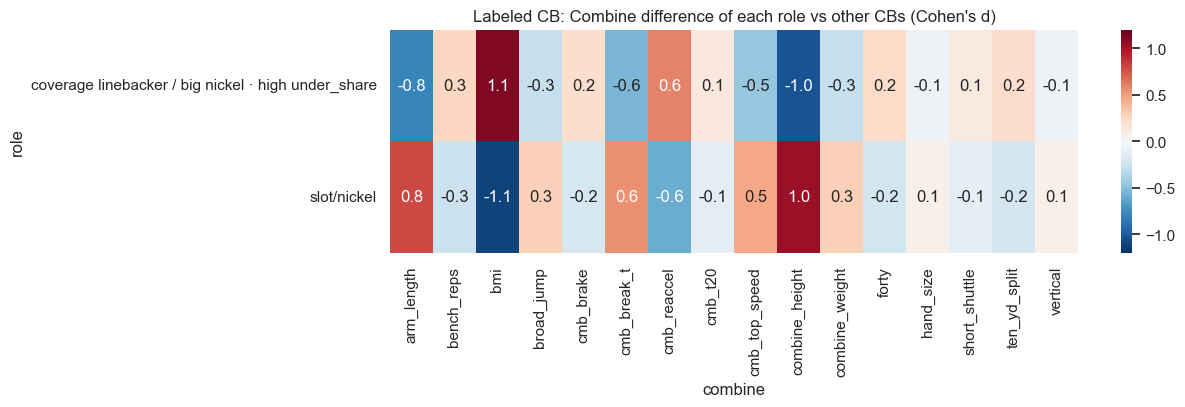

In [10]:
# Within-label: does the same label playing different roles mean a different athlete?
def cohens_d(a, b):
    na, nb = len(a), len(b); sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.nan
rows = []
for L in ["LB", "S", "CB", "EDGE", "DL"]:
    d = cm[cm["label"] == L]
    for r_ in d["role"].value_counts()[lambda s: s >= 5].index:
        a_, b_ = d[d["role"] == r_], d[d["role"] != r_]
        if len(b_) < 5: continue
        for c in CALL:
            x, y = a_[c].dropna(), b_[c].dropna()
            if len(x) < 4 or len(y) < 4: continue
            dd = cohens_d(x, y)
            bs = [cohens_d(x.sample(len(x), replace=True, random_state=i), y.sample(len(y), replace=True, random_state=i + 999)) for i in range(400)]
            lo, hi = np.nanpercentile(bs, [2.5, 97.5])
            rows.append({"label": L, "role": r_, "combine": c, "d": dd, "lo": lo, "hi": hi, "n_role": len(x), "n_other": len(y)})
wl = pd.DataFrame(rows)
if len(wl):
    wl["CI excludes 0"] = (wl["lo"] > 0) | (wl["hi"] < 0)
    print(f"Within-label Combine differences tested: {len(wl)} | CI excluding 0: {int(wl['CI excludes 0'].sum())} (~{0.05 * len(wl):.0f} expected by chance)")
    display(wl[wl["CI excludes 0"]].sort_values(["label", "role", "d"]).round(2))
    for L in ["LB", "S", "CB"]:
        h = wl[wl["label"] == L].pivot_table(index="role", columns="combine", values="d")
        if h.empty: continue
        plt.figure(figsize=(min(1.5 + .6 * h.shape[1], 22), .55 * h.shape[0] + 1.8))
        sns.heatmap(h, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-1.2, vmax=1.2)
        plt.title(f"Labeled {L}: Combine difference of each role vs other {L}s (Cohen's d)"); plt.show()

## 7. Can the Combine predict role?

This is a multinomial logistic regression, cross-validated with players held out whole, comparing:
1. **roster label only** (the baseline: what the label already tells you)
2. **Combine only** (measurements + Combine tracking)
3. **label + Combine**

If set 3 beats set 1, the Combine knows something about role that the label doesn't. The confusion matrix shows which roles the Combine can and can't separate.

roles: 6 | players: 133 | chance (largest class): 0.23


,features,accuracy,macro_F1
0,label only,0.722,0.521
1,Combine only,0.511,0.436
2,label + Combine,0.677,0.558


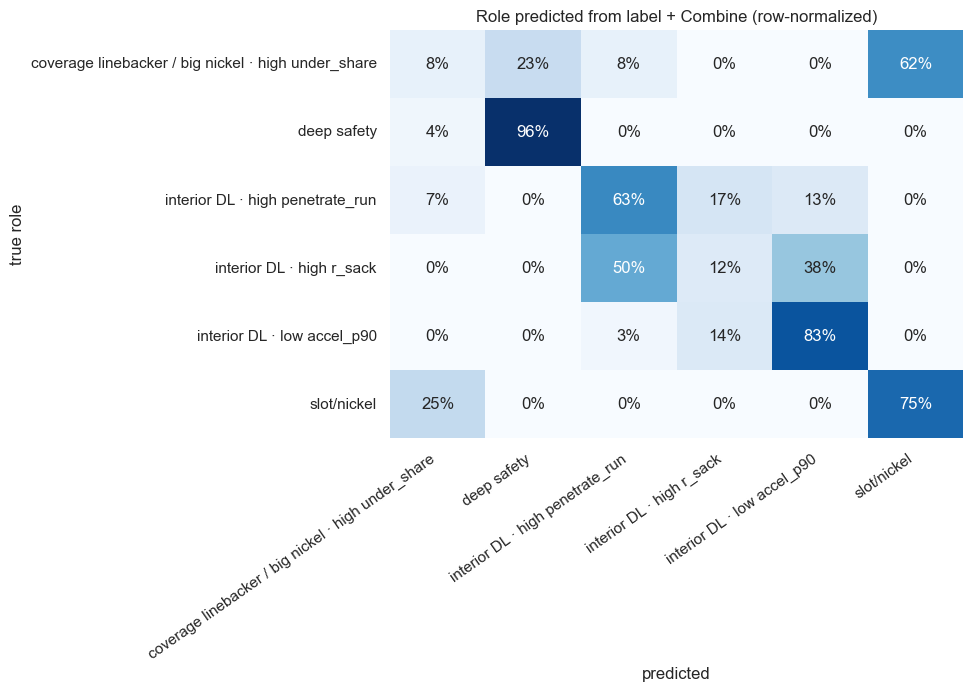

In [11]:
d = cm.dropna(subset=["role"]).copy()
d = d[d["role"].map(d["role"].value_counts()) >= 8]
y = d["role"].to_numpy(); grp = d.index.to_numpy()
Lab = pd.get_dummies(d["label"], prefix="lab").astype(float)
sets = {"label only": Lab, "Combine only": d[CALL], "label + Combine": pd.concat([Lab, d[CALL]], axis=1)}
cv = GroupKFold(n_splits=min(5, len(np.unique(grp))))
res_cv, preds = [], {}
for name, X in sets.items():
    mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000, C=.5, class_weight="balanced"))
    p = cross_val_predict(mdl, X, y, cv=cv, groups=grp); preds[name] = p
    res_cv.append({"features": name, "accuracy": accuracy_score(y, p), "macro_F1": f1_score(y, p, average="macro")})
print(f"roles: {d['role'].nunique()} | players: {len(d)} | chance (largest class): {pd.Series(y).value_counts(normalize=True).iloc[0]:.2f}")
display(pd.DataFrame(res_cv).round(3))
cmx = pd.crosstab(pd.Series(y, name="true role"), pd.Series(preds["label + Combine"], name="predicted"), normalize="index")
plt.figure(figsize=(min(2 + .9 * cmx.shape[1], 20), .55 * cmx.shape[0] + 2))
sns.heatmap(cmx, annot=True, fmt=".0%", cmap="Blues", cbar=False); plt.title("Role predicted from label + Combine (row-normalized)")
plt.xticks(rotation=35, ha="right"); plt.show()

## 8. Blind spots: what roles depend on that the Combine can't see

For every in-game role feature:
- **Role importance** = η², the share of its variance explained by role. High means the feature *defines* roles.
- **Combine visibility** = cross-validated R² from predicting it with all Combine measures plus label, using ridge regression with players held out.

Features with **high role importance and low Combine visibility** are the blind spots: they decide what job a player ends up doing, and nothing at the Combine measures them. Those are the targets for new drills.

,feature,role_importance_eta2,combine+label_R2,combine_only_R2,n,blind_spot_score
25,r_sack,0.699,0.173,0.076,133,0.578
24,r_tfl,0.579,0.120,0.070,133,0.509
17,under_share,0.786,0.380,0.356,133,0.487
26,r_quick_pressure,0.495,0.253,0.101,133,0.370
22,r_tackle,0.557,0.414,0.416,133,0.326
21,lat_range_run,0.630,0.563,0.546,133,0.275
4,get_off,0.799,0.692,0.386,133,0.246
2,accel_p90,0.660,0.651,0.611,133,0.230
8,width_pass,0.910,0.756,0.462,133,0.222
23,r_assist,0.224,0.088,0.015,133,0.204


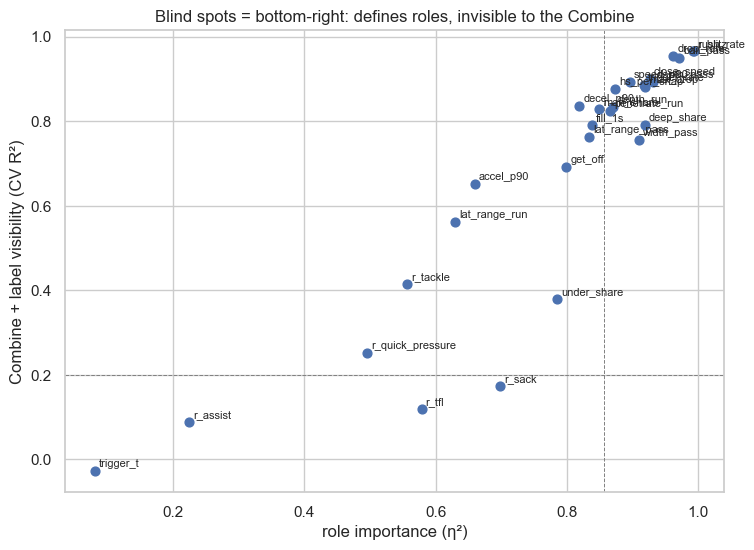

In [12]:
rows = []
dd = cm.copy()
for f in FEAT:
    s = dd[[f, "role"]].dropna()
    if len(s) < 20: continue
    grand = s[f].mean()
    eta2 = s.groupby("role")[f].apply(lambda v: len(v) * (v.mean() - grand) ** 2).sum() / ((s[f] - grand) ** 2).sum()
    X = pd.concat([pd.get_dummies(dd["label"], prefix="lab").astype(float), dd[CALL]], axis=1).loc[s.index]
    mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))
    pr = cross_val_predict(mdl, X, s[f], cv=GroupKFold(n_splits=min(5, len(s))), groups=s.index.to_numpy())
    Xc = dd[CALL].loc[s.index]
    pr_c = cross_val_predict(make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12))),
                             Xc, s[f], cv=GroupKFold(n_splits=min(5, len(s))), groups=s.index.to_numpy())
    rows.append({"feature": f, "role_importance_eta2": eta2, "combine+label_R2": r2_score(s[f], pr), "combine_only_R2": r2_score(s[f], pr_c), "n": len(s)})
bs = pd.DataFrame(rows)
bs["blind_spot_score"] = bs["role_importance_eta2"] * (1 - bs["combine+label_R2"].clip(lower=0))
bs = bs.sort_values("blind_spot_score", ascending=False)
display(bs.round(3))
plt.figure(figsize=(8.5, 6))
plt.scatter(bs["role_importance_eta2"], bs["combine+label_R2"].clip(lower=-.1), s=40)
for _, r in bs.iterrows(): plt.annotate(r["feature"], (r["role_importance_eta2"], max(r["combine+label_R2"], -.1)), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.axhline(.2, color="grey", ls="--", lw=.7); plt.axvline(bs["role_importance_eta2"].median(), color="grey", ls="--", lw=.7)
plt.xlabel("role importance (η²)"); plt.ylabel("Combine + label visibility (CV R²)")
plt.title("Blind spots = bottom-right: defines roles, invisible to the Combine"); plt.show()

## 9. Prototype check with existing drills, and new drill proposals

**Prototype.** The Combine already records drills with backward-to-forward reversals (DB/LB position drills, shuttle). The `cmb_break_t` measure (from the slowest point of a reversal to moving ≥ 3 yd/s the other way) is the closest existing analog to the in-game **trigger**. If it correlates with in-game `trigger_t`, even weakly, that's evidence that a purpose-built read-and-trigger drill would work. If it doesn't, the current drills are the wrong shape: pre-scripted, with no read.

Each proposed drill below targets a family of blind-spot features. The table ranks them by this run's blind-spot scores.

In [13]:
pairs = [("cmb_break_t", "trigger_t"), ("cmb_brake", "decel_p90"), ("cmb_reaccel", "accel_p90"), ("cmb_top_speed", "speed_p90"),
         ("short_shuttle", "lat_range_pass"), ("three_cone", "trigger_t"), ("ten_yd_split", "get_off")]
rows = []
for a_, b_ in pairs:
    if a_ in cm and b_ in cm:
        s = cm[[a_, b_, "label"]].dropna()
        if len(s) >= 15:
            r_all = stats.spearmanr(s[a_], s[b_])[0]
            r_within = np.nanmean([stats.spearmanr(g[a_], g[b_])[0] for _, g in s.groupby("label") if len(g) >= 8]) if s["label"].nunique() > 1 else np.nan
            rows.append({"combine measure": a_, "in-game feature": b_, "ρ (all)": r_all, "mean ρ within label": r_within, "n": len(s)})
proto = pd.DataFrame(rows)
display(proto.round(2))

DRILLS = {
  "Read-and-Trigger": (["trigger_t", "trigger_rate", "bail_pass", "max_drop", "fill_1s"],
      "Backpedal or shuffle from a 5–7 yd alignment; on a random light/audio cue, plant and drive forward at 45° for 5 yd. "
      "Sensor-score cue→first forward step, plant-to-3 yd/s time, and drive speed. Run cues both directions. It adds a READ the current pre-scripted drills don't have."),
  "Rush-or-Drop transition": (["rush_rate", "drop_rate", "t_cross", "penetrate_run"],
      "From a 2-point stance on the LOS, a cue sends him either downhill to a bag at 5 yd or dropping to a 7–10 yd landmark and opening. "
      "Score both transitions. It separates true hybrids (quick both ways) from one-way players."),
  "Range-and-Close": (["lat_range_pass", "lat_range_run", "close_speed", "deep_share", "speed_p90", "hs_per_snap"],
      "Open hips and run to a landmark 10–12 yd wide/deep; on a thrown-ball cue (machine), break and close 8 yd. "
      "Score range covered in 2.5 s and closing speed in the last 5 yd, which is the 'speed in coverage' the 40 can't isolate."),
  "Scrape-and-Fill": (["fill_1s", "depth_run", "r_tackle", "r_run_stop", "r_tfl"],
      "Scrape laterally 5 yd behind a line of bags; on cue, redirect downhill through a 2-yd gap and stop in a 2-yd box. "
      "Score redirect time, downhill acceleration and stopping distance, the box defender's movement without contact."),
  "Press-mirror-and-carry": (["man_share", "width_pass", "depth_pass", "decel_p90", "accel_p90"],
      "Mirror a sensor-wearing receiver's release in a 5-yd box, then carry a vertical 15 yd. "
      "Score lateral lag behind the receiver and the separation after the vertical, a direct test of the outside-corner job."),
}
rows = []
for drill, (feats, desc) in DRILLS.items():
    hit = bs[bs["feature"].isin(feats)]
    rows.append({"proposed drill": drill, "targets": ", ".join(hit["feature"]) or "(features unavailable)",
                 "mean blind-spot score": hit["blind_spot_score"].mean() if len(hit) else np.nan,
                 "best Combine visibility of targets (R²)": hit["combine+label_R2"].max() if len(hit) else np.nan, "design": desc})
props = pd.DataFrame(rows).sort_values("mean blind-spot score", ascending=False)
with pd.option_context("display.max_colwidth", 200): display(props.round(3))

,combine measure,in-game feature,ρ (all),mean ρ within label,n
0,cmb_break_t,trigger_t,-0.11,-0.09,92
1,cmb_brake,decel_p90,0.20,0.11,133
2,cmb_reaccel,accel_p90,0.46,0.16,133
3,cmb_top_speed,speed_p90,0.78,0.17,107
4,short_shuttle,lat_range_pass,-0.70,-0.24,44
5,three_cone,trigger_t,-0.07,-0.02,25
6,ten_yd_split,get_off,-0.63,0.15,109


,proposed drill,targets,mean blind-spot score,best Combine visibility of targets (R²),design
3,Scrape-and-Fill,"r_tfl, r_tackle, fill_1s, depth_run",0.289,0.834,"Scrape laterally 5 yd behind a line of bags; on cue, redirect downhill through a 2-yd gap and stop in a 2-yd box. Score redirect time, downhill acceleration and stopping distance, the box defender..."
4,Press-mirror-and-carry,"accel_p90, width_pass, man_share, decel_p90, depth_pass",0.166,0.894,"Mirror a sensor-wearing receiver's release in a 5-yd box, then carry a vertical 15 yd. Score lateral lag behind the receiver and the separation after the vertical, a direct test of the outside-cor..."
2,Range-and-Close,"lat_range_run, lat_range_pass, deep_share, hs_per_snap, speed_p90, close_speed",0.160,0.900,"Open hips and run to a landmark 10–12 yd wide/deep; on a thrown-ball cue (machine), break and close 8 yd. Score range covered in 2.5 s and closing speed in the last 5 yd, which is the 'speed in co..."
0,Read-and-Trigger,"fill_1s, max_drop, trigger_rate, trigger_t, bail_pass",0.104,0.949,"Backpedal or shuffle from a 5–7 yd alignment; on a random light/audio cue, plant and drive forward at 45° for 5 yd. Sensor-score cue→first forward step, plant-to-3 yd/s time, and drive speed. Run ..."
1,Rush-or-Drop transition,"penetrate_run, drop_rate, rush_rate",0.077,0.966,"From a 2-point stance on the LOS, a cue sends him either downhill to a bag at 5 yd or dropping to a 7–10 yd landmark and opening. Score both transitions. It separates true hybrids (quick both ways..."


In [14]:
# Who would the top drill matter most for? Roles most defined by its target features (centroid z)
top_drill = props.iloc[0]
feats = [f for f in DRILLS[top_drill["proposed drill"]][0] if f in cz.columns]
if feats:
    print(f"Top-ranked proposal: {top_drill['proposed drill']} → role centroid z on its target features")
    display(cz.rename(index=names)[feats].round(2).assign(abs_mean=lambda d: d.abs().mean(axis=1)).sort_values("abs_mean", ascending=False))

ps.to_csv("defender_roles_player_season.csv", index=False)
cm.reset_index().to_csv("defender_roles_combine.csv", index=False)
bs.to_csv("defender_role_blind_spots.csv", index=False)
print("Saved defender_roles_player_season.csv, defender_roles_combine.csv, defender_role_blind_spots.csv")

Top-ranked proposal: Scrape-and-Fill → role centroid z on its target features


,fill_1s,depth_run,r_tackle,r_tfl,abs_mean
role_id,,,,,
interior DL · high r_sack,1.17,-0.81,-0.19,2.43,1.1500
coverage linebacker / big nickel · high under_share,0.94,0.03,2.91,0.28,1.0400
deep safety,-0.79,1.75,0.69,-0.57,0.9500
interior DL · high penetrate_run,1.12,-0.80,-0.64,0.44,0.7500
slot/nickel,-1.11,0.28,0.38,-0.63,0.6000
interior DL · low accel_p90,0.50,-0.80,-1.00,-0.08,0.5950
coverage linebacker / big nickel · high under_share,-0.45,0.08,1.08,-0.20,0.4525


Saved defender_roles_player_season.csv, defender_roles_combine.csv, defender_role_blind_spots.csv


### Reading this notebook
- **Roles are a lens, not ground truth.** Check §4's centroid heatmap and rename roles that the automatic names get wrong. The rename doesn't change the analysis.
- **The interesting rows are the mismatches** (§5): safeties in box roles, linebackers in coverage roles, hybrids with split membership. These are the players a roster label misdescribes.
- **§6 within-label differences** are the Combine story: if box-role safeties are heavier or slower than deep-role safeties, the Combine already sees role. If not, the role is learned or schematic.
- **§8 blind spots** are the drill story. Features that define roles but that the Combine can't predict (low R²) are where a new drill adds value. The §9 prototype correlation is a feasibility check using drills that already exist.
- **Multiple comparisons:** §6 tests many role × measure pairs and prints the number expected by chance. Trust patterns that repeat across labels or line up with §8.